# Fig. S6: wave-packet reflection for leads on the top and on the bottom layer


    Energy-resolved reflection probability R(E) of the wave packet incident on the domain wall from the
    two sides, with the graphene lead coupled to the top layer (left, the data of Fig. 4c) and to the
    bottom layer (right).

    Data: `refl.dat` (top-layer lead) and `2026_09_09_Is_lead1-6.xlsx` (columns: E (eV); R for
    ABCABC→ABCABA and ABCABA→ABCABC with the lead on layer 6 = top, then the same with the lead on
    layer 1 = bottom; the WPD code numbers the layers from the bottom). Negative values, which come from
    the re-reflection of the wall-reflected packet at the lead contact, are clipped to zero in the figure.


Paper: Kandrai, K. *et al.* One-way electron mirrors from single-layer stacking shifts in rhombohedral graphite. Preprint at https://arxiv.org/abs/2610.20905 (2026).

In [1]:
import os
import sys
import requests
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MultipleLocator

In [2]:
print('python', sys.version.split()[0])
print('numpy', np.__version__)
print('matplotlib', matplotlib.__version__)
print('pandas', pd.__version__)

python 3.13.5
numpy 2.1.3
matplotlib 3.10.0
pandas 2.2.3


In [3]:
# figure style of the paper: scienceplots if it is installed, plain matplotlib otherwise
try:
    import scienceplots  # noqa: F401
    plt.style.use(['science', 'no-latex', 'nature', 'std-colors'])
except ImportError:
    pass
matplotlib.rcParams['pdf.fonttype'] = 42   # editable text in Inkscape / Illustrator
matplotlib.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['figure.dpi'] = 110

In [4]:
# Data files are downloaded from Zenodo into DATA_DIR if they are not there yet.
ZENODO_RECORD = '23419464'   # record number of the data set, https://zenodo.org/records/<ZENODO_RECORD>
DATA_DIR = 'data'

FILES = ['refl.dat', '2026_09_09_Is_lead1-6.xlsx']


def get_data(filename, record=ZENODO_RECORD, data_dir=DATA_DIR):
    """Return the local path of a data file, downloading it from Zenodo first if needed."""
    path = os.path.join(data_dir, filename)
    if os.path.exists(path):
        return path
    os.makedirs(data_dir, exist_ok=True)
    url = f'https://zenodo.org/records/{record}/files/{requests.utils.quote(filename)}?download=1'
    print(f'Downloading {filename} ...')
    with requests.get(url, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(path, 'wb') as fh:
            for chunk in r.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
    print(f'  saved to {path}')
    return path


for f in FILES:
    get_data(f)

In [5]:
top = np.loadtxt(get_data('refl.dat'))
df = pd.read_excel(get_data('2026_09_09_Is_lead1-6.xlsx'), header=None)
print(df.head(3).to_string())
energy = pd.to_numeric(df.iloc[:, 0], errors='coerce')
bottom = {
    'blue': pd.DataFrame({'E': energy, 'R': pd.to_numeric(df.iloc[:, 3], errors='coerce')}).dropna(),  # (+5) -> (+4-), bottom lead
    'red': pd.DataFrame({'E': energy, 'R': pd.to_numeric(df.iloc[:, 4], errors='coerce')}).dropna(),   # (+4-) -> (+5), bottom lead
}
# consistency check: the lead-6 columns of the spreadsheet are the refl.dat curves
top_xlsx = pd.DataFrame({'E': energy, 'b': pd.to_numeric(df.iloc[:, 1], errors='coerce'),
                         'r': pd.to_numeric(df.iloc[:, 2], errors='coerce')}).dropna()
if len(top_xlsx) == len(top):
    print('max |xlsx lead6 - refl.dat|:',
          np.max(np.abs(top_xlsx['b'].to_numpy() - top[:, 1])), np.max(np.abs(top_xlsx['r'].to_numpy() - top[:, 2])))
else:
    print('spreadsheet rows', len(top_xlsx), 'refl.dat rows', len(top))

        0               1                 2               3                 4
0     NaN  ABCABC  ABCABA  ABCABA -- ABCABC  ABCABC  ABCABA  ABCABA -- ABCABC
1     NaN           lead6             lead6           lead1             lead1
2  E [eV]               R                 R               R                 R
max |xlsx lead6 - refl.dat|: 0.0 0.0


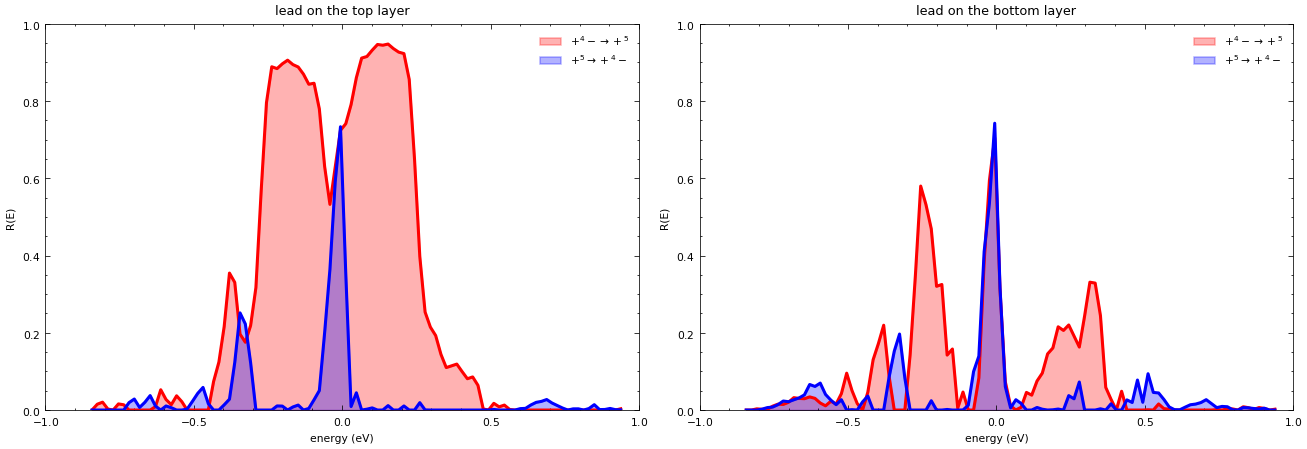

In [6]:
label_red = r'$+^{4}- \rightarrow +^{5}$'
label_blue = r'$+^{5} \rightarrow +^{4}-$'

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
panels = [
    (axs[0], 'lead on the top layer', top[:, 0], top[:, 2], top[:, 0], top[:, 1]),
    (axs[1], 'lead on the bottom layer', bottom['red']['E'].to_numpy(), bottom['red']['R'].to_numpy(),
     bottom['blue']['E'].to_numpy(), bottom['blue']['R'].to_numpy()),
]
for ax, title, E_red, R_red, E_blue, R_blue in panels:
    for E_, R_, color, label in ((E_red, R_red, 'red', label_red), (E_blue, R_blue, 'blue', label_blue)):
        R_ = np.maximum(R_, 0)
        ax.fill_between(E_, 0, R_, color=color, alpha=0.3, label=label)
        ax.plot(E_, R_, color=color, lw=2)
    ax.set_xlim(-1, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('energy (eV)'); ax.set_ylabel('R(E)')
    ax.set_title(title)
    ax.xaxis.set_major_locator(MultipleLocator(0.5)); ax.yaxis.set_major_locator(MultipleLocator(0.2))
    ax.legend(loc='upper right', frameon=False, fontsize=7)
plt.tight_layout()
plt.show()

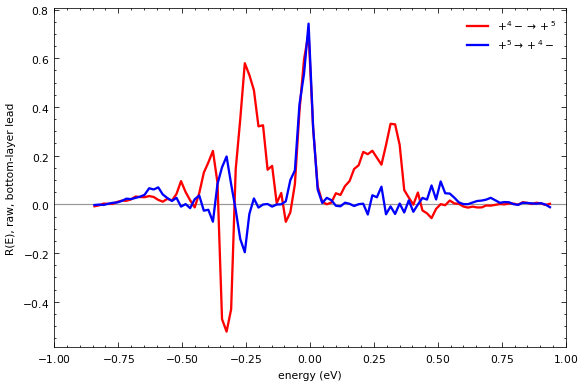

In [7]:
# raw curves of the bottom-layer lead, negative values included
fig, ax = plt.subplots(figsize=(6, 4))
ax.axhline(0, color='0.6', lw=0.8)
ax.plot(bottom['red']['E'], bottom['red']['R'], color='red', lw=1.5, label=label_red)
ax.plot(bottom['blue']['E'], bottom['blue']['R'], color='blue', lw=1.5, label=label_blue)
ax.set_xlim(-1, 1)
ax.set_xlabel('energy (eV)'); ax.set_ylabel('R(E), raw, bottom-layer lead')
ax.legend(frameon=False)
plt.show()